In [1]:
%pip install scikit-learn

  Using cached scikit_learn-1.3.2-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (11 kB)
  Using cached numpy-1.24.4-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.6 kB)
  Using cached scipy-1.10.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (58 kB)
  Using cached joblib-1.4.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached threadpoolctl-3.5.0-py3-none-any.whl.metadata (13 kB)
Using cached scikit_learn-1.3.2-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (11.1 MB)
Using cached joblib-1.4.2-py3-none-any.whl (301 kB)
Using cached numpy-1.24.4-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.3 MB)
Using cached scipy-1.10.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (34.5 MB)
Using cached threadpoolctl-3.5.0-py3-none-any.whl (18 kB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (
    load_diabetes,
    load_breast_cancer,
    load_digits,
    load_iris
)

from sklearn.model_selection import train_test_split

In [3]:
%pip install numpy pandas matplotlib scikit-learn

  Using cached pandas-2.0.3-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
  Using cached matplotlib-3.7.5-cp38-cp38-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (5.7 kB)
  Using cached contourpy-1.1.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.9 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.57.0-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (102 kB)
  Using cached kiwisolver-1.4.7-cp38-cp38-manylinux_2_5_x86_64.manylinux1_x86_64.whl.metadata (6.3 kB)
  Using cached pillow-10.4.0-cp38-cp38-manylinux_2_28_x86_64.whl.metadata (9.2 kB)
  Using cached pyparsing-3.1.4-py3-none-any.whl.metadata (5.1 kB)
  Using cached importlib_resources-6.4.5-py3-none-any.whl.metadata (4.0 kB)
Using cached pandas-2.0.3-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.4 MB)
Using cached matplotlib-3.7.5-cp38-cp38-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (9.2 M

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (
    load_diabetes,
    load_breast_cancer,
    load_digits,
    load_iris
)

from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load Diabetes Dataset
diabetes = load_diabetes(scaled=False)

X_diabetes = diabetes.data
y_diabetes = diabetes.target


# Load Breast Cancer Dataset
cancer = load_breast_cancer()

X_cancer = cancer.data
y_cancer = 1 - cancer.target


# Load Digits Dataset
digits = load_digits()

X_digits = digits.data / 16.0
y_digits = digits.target


# Load Iris Dataset
iris = load_iris()

X_iris = iris.data
y_iris = iris.target

In [4]:
print("Diabetes:", X_diabetes.shape, y_diabetes.shape)
print("Breast Cancer:", X_cancer.shape, y_cancer.shape)
print("Digits:", X_digits.shape, y_digits.shape)
print("Iris:", X_iris.shape, y_iris.shape)

Diabetes: (442, 10) (442,)
Breast Cancer: (569, 30) (569,)
Digits: (1797, 64) (1797,)
Iris: (150, 4) (150,)


In [5]:
def split_data(X, y, is_classification=True):

    stratify_value = y if is_classification else None

    # First split: 80% training + validation, 20% testing
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify_value
    )

    stratify_train = y_train_val if is_classification else None

    # Second split: 75% training, 25% validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val,
        test_size=0.25,
        random_state=42,
        stratify=stratify_train
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

In [6]:
datasets = {
    "Diabetes": (X_diabetes, y_diabetes, False),
    "Breast Cancer": (X_cancer, y_cancer, True),
    "Digits": (X_digits, y_digits, True),
    "Iris": (X_iris, y_iris, True)
}

splits = {}

for name, (X, y, is_classification) in datasets.items():

    splits[name] = split_data(X, y, is_classification)

    print(f"\n{name}")

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]

    print("Training:", len(X_train))
    print("Validation:", len(X_val))
    print("Testing:", len(X_test))

    if is_classification:

        print("Class counts:")

        for split_name, labels in [
            ("Train", y_train),
            ("Validation", y_val),
            ("Test", y_test)
        ]:

            classes, counts = np.unique(labels, return_counts=True)

            print(split_name, dict(zip(classes, counts)))


Diabetes
Training: 264
Validation: 89
Testing: 89

Breast Cancer
Training: 341
Validation: 114
Testing: 114
Class counts:
Train {np.int64(0): np.int64(214), np.int64(1): np.int64(127)}
Validation {np.int64(0): np.int64(71), np.int64(1): np.int64(43)}
Test {np.int64(0): np.int64(72), np.int64(1): np.int64(42)}

Digits
Training: 1077
Validation: 360
Testing: 360
Class counts:
Train {np.int64(0): np.int64(106), np.int64(1): np.int64(109), np.int64(2): np.int64(107), np.int64(3): np.int64(109), np.int64(4): np.int64(109), np.int64(5): np.int64(109), np.int64(6): np.int64(109), np.int64(7): np.int64(107), np.int64(8): np.int64(104), np.int64(9): np.int64(108)}
Validation {np.int64(0): np.int64(36), np.int64(1): np.int64(37), np.int64(2): np.int64(35), np.int64(3): np.int64(37), np.int64(4): np.int64(36), np.int64(5): np.int64(36), np.int64(6): np.int64(36), np.int64(7): np.int64(36), np.int64(8): np.int64(35), np.int64(9): np.int64(36)}
Test {np.int64(0): np.int64(36), np.int64(1): np.int6

In [7]:
class Standardizer:
    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)

        self.std[self.std == 0] = 1

        return self

    def transform(self, X):
        return (X - self.mean) / self.std

In [8]:
X_diabetes_train, X_diabetes_val, X_diabetes_test, y_diabetes_train, y_diabetes_val, y_diabetes_test = splits["Diabetes"]

scaler = Standardizer()

X_train_scaled = scaler.fit(X_diabetes_train).transform(X_diabetes_train)

print("Means:", np.mean(X_train_scaled, axis=0))
print("Standard deviations:", np.std(X_train_scaled, axis=0))


Means: [-2.26249995e-16  1.79990702e-16 -2.23726761e-15 -3.61663561e-16
 -5.88754634e-17 -1.08348348e-17  1.94394164e-16 -4.03717464e-17
  2.03877319e-15 -5.53100810e-16]
Standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [9]:
def add_bias(X):
    return np.column_stack((np.ones(X.shape[0]), X))

In [10]:
X_test_bias = add_bias(np.array([[2, 3], [4, 5]]))

print(X_test_bias)


[[1. 2. 3.]
 [1. 4. 5.]]


In [11]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - (ss_res / ss_total)

In [12]:
y_true = np.array([1, 2, 3])
y_pred = np.array([1, 2, 4])

print("MSE:", mse(y_true, y_pred))
print("RMSE:", rmse(y_true, y_pred))
print("R2:", r2(y_true, y_pred))


MSE: 0.3333333333333333
RMSE: 0.5773502691896257
R2: 0.5


# Numerical gradient checking

In [13]:
def grad_check(f, grad, w, eps=1e-5):
    numerical_grad = np.zeros_like(w, dtype=float)

    for i in range(len(w)):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += eps
        w_minus[i] -= eps

        numerical_grad[i] = (f(w_plus) - f(w_minus)) / (2 * eps)

    analytical_grad = grad(w)

    relative_error = np.linalg.norm(numerical_grad - analytical_grad) / max(
        np.linalg.norm(numerical_grad),
        np.linalg.norm(analytical_grad),
        1e-12
    )

    return relative_error

In [14]:
w_test = np.random.default_rng(42).normal(0, 0.1, 5)

f_test = lambda w: np.sum(w ** 2)
grad_test = lambda w: 2 * w

error = grad_check(f_test, grad_test, w_test)

print("Relative error:", error)

assert error < 1e-6, "Gradient check failed!"

print("Gradient check passed!")

Relative error: 1.1752888136783617e-12
Gradient check passed!


# Part B Linear regression

## Normal equation

### Implementing it

In [17]:
def normal_equation(X, y):
    X_bias = np.column_stack((np.ones(X.shape[0]), X))

    A = X_bias.T @ X_bias
    b = X_bias.T @ y

    w = np.linalg.solve(A, b)

    return w

### Mathematical derivation

In [18]:
X_test = np.array([[1], [2], [3]], dtype=float)
y_test = np.array([2, 3, 5], dtype=float)

w_test = normal_equation(X_test, y_test)

print("Weights:", w_test)
print("Bias:", w_test[0])
print("Slope:", w_test[1])

Weights: [0.33333333 1.5       ]
Bias: 0.3333333333333333
Slope: 1.5


## Batch gradient descent

In [19]:
def linear_loss(X, y, w):
    predictions = X @ w
    loss = np.sum((predictions - y) ** 2) / (2 * len(y))
    return loss

In [20]:
def linear_gradient(X, y, w):
    predictions = X @ w
    gradient = (X.T @ (predictions - y)) / len(y)
    return gradient

In [21]:
def batch_gradient_descent(X, y, eta, epochs, w_star=None):
    w = np.zeros(X.shape[1])

    loss_history = []
    distance_history = []

    for epoch in range(epochs):
        gradient = linear_gradient(X, y, w)
        w = w - eta * gradient

        loss_history.append(linear_loss(X, y, w))

        if w_star is not None:
            distance = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)
            distance_history.append(distance)

    return w, np.array(loss_history), np.array(distance_history)

### Preparing diabetes dataset

In [22]:
# the splits
X_diabetes_train, X_diabetes_val, X_diabetes_test, y_diabetes_train, y_diabetes_val, y_diabetes_test = splits["Diabetes"]

# Standardize the features
diabetes_scaler = Standardizer()

X_diabetes_train_scaled = diabetes_scaler.fit(X_diabetes_train).transform(X_diabetes_train)
X_diabetes_val_scaled = diabetes_scaler.transform(X_diabetes_val)
X_diabetes_test_scaled = diabetes_scaler.transform(X_diabetes_test)

# Adding bias
X_diabetes_train_bias = add_bias(X_diabetes_train_scaled)
X_diabetes_val_bias = add_bias(X_diabetes_val_scaled)
X_diabetes_test_bias = add_bias(X_diabetes_test_scaled)

print("Training shape:", X_diabetes_train_bias.shape)
print("Validation shape:", X_diabetes_val_bias.shape)
print("Test shape:", X_diabetes_test_bias.shape)


Training shape: (264, 11)
Validation shape: (89, 11)
Test shape: (89, 11)


### getting optimal weights using Normal Equation

In [23]:
w_star = normal_equation(X_diabetes_train_scaled, y_diabetes_train)

print("Optimal weights:", w_star)
print("Number of weights:", len(w_star))

Optimal weights: [149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Number of weights: 11


### Checking linear regression gradient

In [24]:
def loss_function(w):
    return linear_loss(X_diabetes_train_bias, y_diabetes_train, w)


def gradient_function(w):
    return linear_gradient(X_diabetes_train_bias, y_diabetes_train, w)


w_check = np.random.default_rng(42).normal(
0, 0.1, X_diabetes_train_bias.shape[1]
)

error = grad_check(loss_function, gradient_function, w_check)

print("Relative error:", error)

assert error < 1e-6, "Gradient check failed!"

print("Linear regression gradient check passed!")

Relative error: 1.4148267969884531e-09
Linear regression gradient check passed!


## Comparing Learning Rates
We'll test different learning rates to see how they affect the convergence of Batch Gradient Descent.
Using  2000 epochs and comparing the final loss and distance from the optimal weights.

In [25]:
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]

results = {}

for eta in learning_rates:
    weights, losses, distances = batch_gradient_descent(
    X_diabetes_train_bias,
    y_diabetes_train,
    eta,
    2000,
    w_star
    )

    results[eta] = (weights, losses, distances)

    print("Learning rate:", eta)
    print("Final loss:", losses[-1])
    print("Final relative distance:", distances[-1])
    print()


Learning rate: 0.001
Final loss: 1723.4028887869279
Final relative distance: 0.405113051014307

Learning rate: 0.01
Final loss: 1503.686675828936
Final relative distance: 0.33452142983685884

Learning rate: 0.1
Final loss: 1491.8926356565878
Final relative distance: 0.08179228655115682

Learning rate: 0.5
Final loss: 1491.1459074694747
Final relative distance: 0.00015462616481585199

Learning rate: 1.0
Final loss: nan
Final relative distance: nan



/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/var/folders/kp/m4wwmmk51s90wx1nlx7x92kw0000gn/T/ipykernel_18497/1933215590.py:3: RuntimeWarning: overflow encountered in square
  loss = np.sum((predictions - y) ** 2) / (2 * len(y))


### Comparing Loss Across Learning Rates

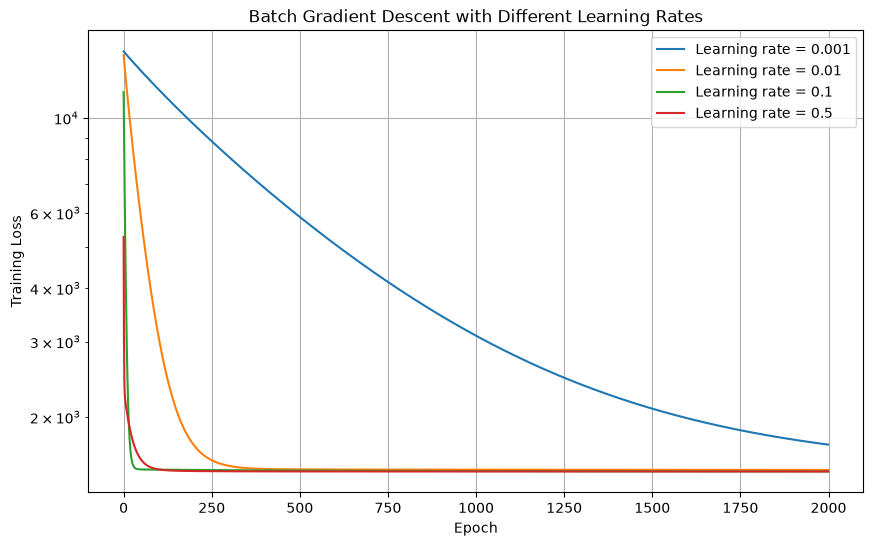

In [27]:
plt.figure(figsize=(10, 6))

for eta in learning_rates:
    losses = results[eta][1]

    if np.all(np.isfinite(losses)):
        plt.plot(losses, label=f"Learning rate = {eta}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Batch Gradient Descent with Different Learning Rates")
plt.legend()
plt.grid(True)

plt.show()

### First Epoch Reaching the Required Accuracy

In [28]:
for eta in learning_rates:
    distances = results[eta][2]

    successful_epochs = np.where(distances < 1e-3)[0]

    if len(successful_epochs) > 0:
        print("Learning rate:", eta)
        print("First successful epoch:", successful_epochs[0] + 1)
    else:
        print("Learning rate:", eta)
        print("Not reached within 2000 epochs")

Learning rate: 0.001
Not reached within 2000 epochs
Learning rate: 0.01
Not reached within 2000 epochs
Learning rate: 0.1
Not reached within 2000 epochs
Learning rate: 0.5
First successful epoch: 1524
Learning rate: 1.0
Not reached within 2000 epochs


In [29]:
# the Hessian matrix
N = X_diabetes_train_bias.shape[0]

H = (X_diabetes_train_bias.T @ X_diabetes_train_bias) / N

# eigenvalues
eigenvalues = np.linalg.eigvalsh(H)

# largest eigenvalue
lambda_max = eigenvalues[-1]

# max learning rate
eta_max = 2 / lambda_max

print("Largest eigenvalue:", lambda_max)
print("Maximum learning rate:", eta_max)

Largest eigenvalue: 3.9547550320503753
Maximum learning rate: 0.5057203249737275


In [30]:
eta_below = 0.95 * eta_max
eta_above = 1.05 * eta_max

# Testing learning rate below the limit
weights_below, losses_below, distances_below = batch_gradient_descent(
X_diabetes_train_bias,
y_diabetes_train,
eta_below,
2000,
w_star
)

# Testing learning rate above the limit
weights_above, losses_above, distances_above = batch_gradient_descent(
X_diabetes_train_bias,
y_diabetes_train,
eta_above,
2000,
w_star
)

print("Learning rate below limit:", eta_below)
print("Final loss:", losses_below[-1])
print("Final relative distance:", distances_below[-1])

print()

print("Learning rate above limit:", eta_above)
print("Final loss:", losses_above[-1])
print("Final relative distance:", distances_above[-1])

Learning rate below limit: 0.4804343087250411
Final loss: 1491.145909733976
Final relative distance: 0.00021023075313679997

Learning rate above limit: 0.531006341222414
Final loss: 3.244811817867851e+168
Final relative distance: 7.58186334243912e+81


The largest eigenvalue of the Hessian was 3.9548, giving a theoretical maximum learning rate of approximately 0.5057. When using 95% of this limit (η = 0.4804), gradient descent converged and reached a relative distance below 10⁻³. However, when using 105% of the limit (η = 0.5310), the loss and relative distance grew, indicating divergence. This confirms that gradient descent converges only when the learning rate is below

### Why scaling/standardizing matters

In [31]:
# Adding bias column to original features
X_diabetes_train_raw_bias = add_bias(X_diabetes_train)

# raw Hessian
H_raw = (
X_diabetes_train_raw_bias.T @ X_diabetes_train_raw_bias
) / len(y_diabetes_train)

# condition number
condition_raw = np.linalg.cond(
X_diabetes_train_raw_bias.T @ X_diabetes_train_raw_bias
)

# largest eigenvalue
eigenvalues_raw = np.linalg.eigvalsh(H_raw)
lambda_max_raw = eigenvalues_raw[-1]

# maximum learning rate
eta_max_raw = 2 / lambda_max_raw

print("Raw feature condition number:", condition_raw)
print("Raw maximum learning rate:", eta_max_raw)


Raw feature condition number: 55778473.21819634
Raw maximum learning rate: 2.7427928748390996e-05


In [32]:
condition_scaled = np.linalg.cond(
X_diabetes_train_bias.T @ X_diabetes_train_bias
)

print("Standardized condition number:", condition_scaled)
print("Raw condition number:", condition_raw)

print()

print("Standardized maximum learning rate:", eta_max)
print("Raw maximum learning rate:", eta_max_raw)


Standardized condition number: 505.70612269607483
Raw condition number: 55778473.21819634

Standardized maximum learning rate: 0.5057203249737275
Raw maximum learning rate: 2.7427928748390996e-05


Standardization reduced the condition number from  55.8 million to 506. 
This makes the loss surface better conditioned and allows a much larger learning rate. 
The maximum learning rate increased from  0.0000274 to 0.5057 after standardization.
Raw features require much smaller learning rates and more epochs to converge, while standardization allows gradient descent to make faster and more stable progress.

### Repeating using the original features

In [33]:
# optimal weights for raw features
w_star_raw = normal_equation(
X_diabetes_train,
y_diabetes_train
)

In [34]:
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]

raw_results = {}

for eta in raw_learning_rates:
    weights, losses, distances = batch_gradient_descent(
    X_diabetes_train_raw_bias,
    y_diabetes_train,
    eta,
    2000,
    w_star_raw
)

    raw_results[eta] = (weights, losses, distances)

    print("Learning rate:", eta)
    print("Final loss:", losses[-1])
    print("Final relative distance:", distances[-1])
    print()

Learning rate: 1e-08
Final loss: 3583.5321022429885
Final relative distance: 0.9999985696135456

Learning rate: 1e-06
Final loss: 2388.75258220855
Final relative distance: 0.9999676302127518

Learning rate: 1e-05
Final loss: 1827.5349100578878
Final relative distance: 0.9998463739822517

Learning rate: 0.0001
Final loss: nan
Final relative distance: nan



/var/folders/kp/m4wwmmk51s90wx1nlx7x92kw0000gn/T/ipykernel_18497/1933215590.py:3: RuntimeWarning: overflow encountered in square
  loss = np.sum((predictions - y) ** 2) / (2 * len(y))
/var/folders/kp/m4wwmmk51s90wx1nlx7x92kw0000gn/T/ipykernel_18497/2997493346.py:9: RuntimeWarning: invalid value encountered in subtract
  w = w - eta * gradient


When using raw features, the learning rates 1e-8, 1e-6, and 1e-5 make very slow progress and remain far from the optimal weights after 2000 epochs.
A learning rate of 1e-4 causes divergence and produces NaN values. 
This shows that raw features require much smaller learning rates than standardized features.
Standardization improves the conditioning of the problem and allows gradient descent to converge much faster.

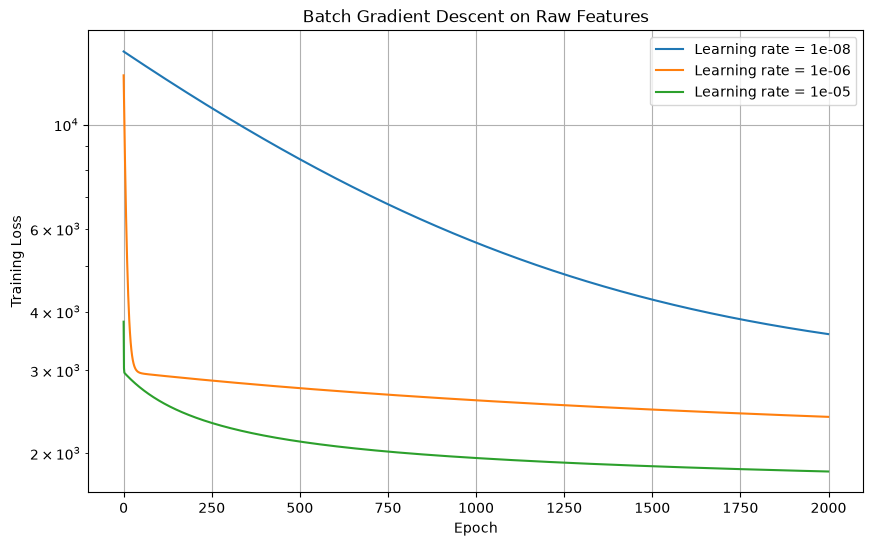

In [36]:
plt.figure(figsize=(10, 6))

for eta in raw_learning_rates:
    losses = raw_results[eta][1]

    if np.all(np.isfinite(losses)):
        plt.plot(losses, label=f"Learning rate = {eta}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Batch Gradient Descent on Raw Features")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
for eta in raw_learning_rates:
    weights, losses, distances = raw_results[eta]

    successful_epochs = np.where(distances < 1e-3)[0]

    if len(successful_epochs) > 0:
        first_epoch = successful_epochs[0] + 1
    else:
        first_epoch = "Not reached"

    print(eta, losses[-1], distances[-1], first_epoch)
#learning rate-final loss-relative distance-first successful epoch 

1e-08 3583.5321022429885 0.9999985696135456 Not reached
1e-06 2388.75258220855 0.9999676302127518 Not reached
1e-05 1827.5349100578878 0.9998463739822517 Not reached
0.0001 nan nan Not reached


### We'll implement a new gradient descent function because the existing one uses the whole dataset for every update.

In [38]:
def mini_batch_gradient_descent(X, y, eta, epochs, batch_size):
    w = np.zeros(X.shape[1])
    loss_history = []

    for epoch in range(epochs):
        indices = np.random.permutation(len(y))
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for i in range(0, len(y), batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            gradient = linear_gradient(X_batch, y_batch, w)
            w = w - eta * gradient

        loss = linear_loss(X, y, w)
        loss_history.append(loss)

    return w, np.array(loss_history)


In [39]:
batch_sizes = [1, 16, 64, len(y_diabetes_train)]

mini_batch_results = {}

for B in batch_sizes:
    weights, losses = mini_batch_gradient_descent(
    X_diabetes_train_bias,
    y_diabetes_train,
    0.01,
    100,
    B
    )

    mini_batch_results[B] = (weights, losses)

    print("Batch size:", B)
    print("Final loss:", losses[-1])
    print()

Batch size: 1
Final loss: 1515.5161011503214

Batch size: 16
Final loss: 1504.4934877446105

Batch size: 64
Final loss: 1508.7858550165715

Batch size: 264
Final loss: 3085.440478999073



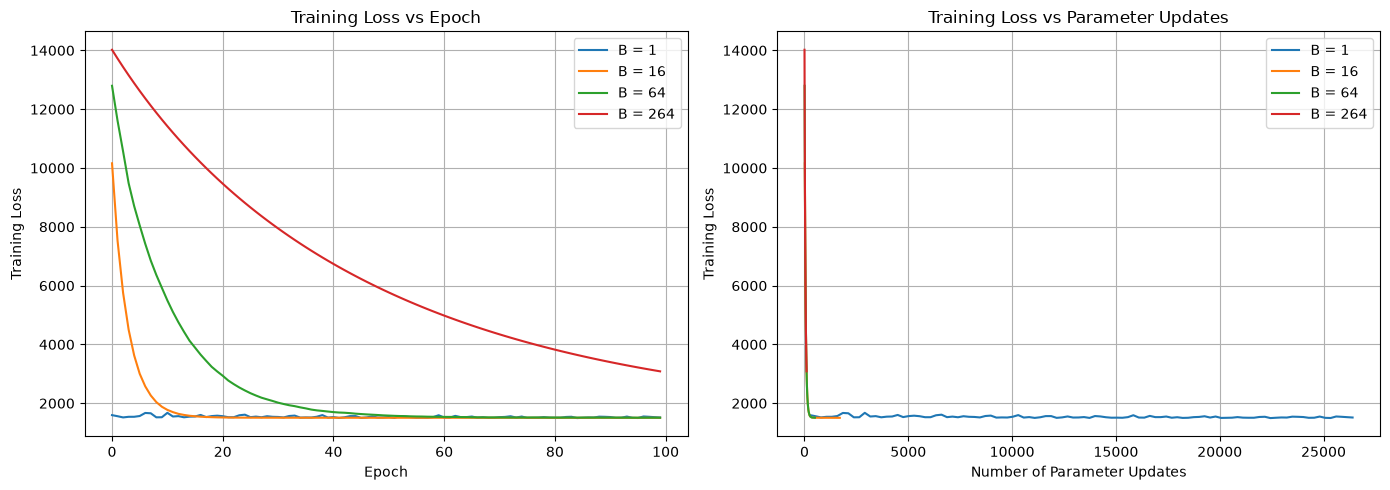

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for B in batch_sizes:
    weights, losses = mini_batch_results[B]

    axes[0].plot(losses, label=f"B = {B}")

    updates = np.arange(1, len(losses) + 1) * np.ceil(len(y_diabetes_train) / B)
    axes[1].plot(updates, losses, label=f"B = {B}")

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss")
axes[0].set_title("Training Loss vs Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Number of Parameter Updates")
axes[1].set_ylabel("Training Loss")
axes[1].set_title("Training Loss vs Parameter Updates")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Smaller batch sizes make more parameter updates during each epoch.

B=1 produces noisier updates because each update uses only one sample. 

Larger batches give smoother updates but require more samples for each update.

In [43]:
learning_rates_sgd = [0.001, 0.01, 0.1]
sgd_results = {}

for eta in learning_rates_sgd:
    weights, losses = mini_batch_gradient_descent(
    X_diabetes_train_bias,
    y_diabetes_train,
    eta,
    100,
    1
    )

    sgd_results[eta] = (weights, losses)

    print("Learning rate:", eta)
    print("Final loss:", losses[-1])
    print()


Learning rate: 0.001
Final loss: 1502.4930416949585

Learning rate: 0.01
Final loss: 1501.832378124309

Learning rate: 0.1
Final loss: 10124.841392605942



With B=1, learning rates 0.001 and 0.01 give similar final losses(0.01 performs slightly better). 

But learning rate 0.1 gives a much higher loss because the updates become unstable. 

This shows that sgd needs a suitable learning rate because individual samples produce noisy updates.